IMPORTING REQUIRED LIBRARIES

In [152]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn  as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score,root_mean_squared_error

LOADING CALIFORNIA DATASET

In [66]:
from sklearn.datasets import fetch_california_housing
Dataset=fetch_california_housing()
Dataset

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]]),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894]),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': '.. _california_housing_dataset:\n

CONVERTING DATASET INTO DATAFRAME

In [68]:

df=pd.DataFrame(Dataset.data,columns=Dataset.feature_names)
df["HouseVal"]=Dataset.target
df.head(100)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
95,2.0096,36.0,2.294016,1.066294,3469.0,1.493328,37.80,-122.26,1.300
96,2.8345,31.0,3.894915,1.127966,2048.0,1.735593,37.82,-122.26,1.838
97,2.0062,29.0,3.681319,1.175824,202.0,2.219780,37.81,-122.26,1.250
98,1.2185,22.0,2.945600,1.016000,2024.0,1.619200,37.82,-122.26,1.700


EXPLORATORY DATA ANALYSIS:

As there are no  null values in the features,so imputation is not required.

In [69]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   HouseVal    20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [168]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
HouseVal,0


In [70]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


DETECTING OUTLIERS:

From the plot,population have higher outliers .So it should be removed as it's better for training the model.otherwise model get biased and leads to poor prediction.

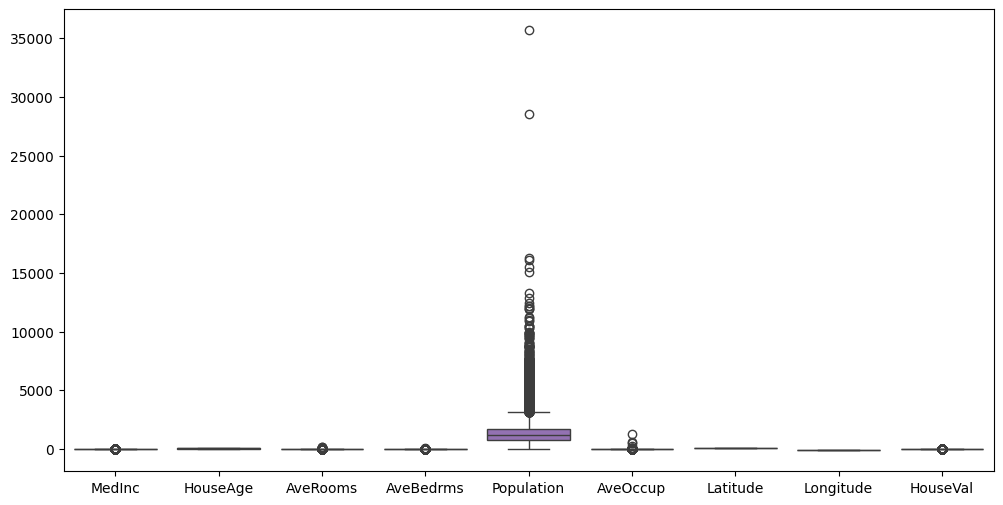

In [71]:
  plt.figure(figsize=(12,6))
  sns.boxplot(data=df)
  plt.show()


FINDING OUTLIERS


In [72]:
Q1=df["Population"].quantile(0.25)
Q3=df["Population"].quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
outliers=df[(df["Population"] <= lower_bound) | (df["Population"] >= upper_bound)]
print(outliers["Population"])
print("Number of outliers:", outliers.shape[0])

95       3469.0
185      4367.0
283      4985.0
460      3337.0
485      3276.0
          ...  
20543    3717.0
20544    6330.0
20563    6837.0
20604    3265.0
20629    6912.0
Name: Population, Length: 1198, dtype: float64
Number of outliers: 1198


REMOVING OUTLIERS:Now the outliers removed.

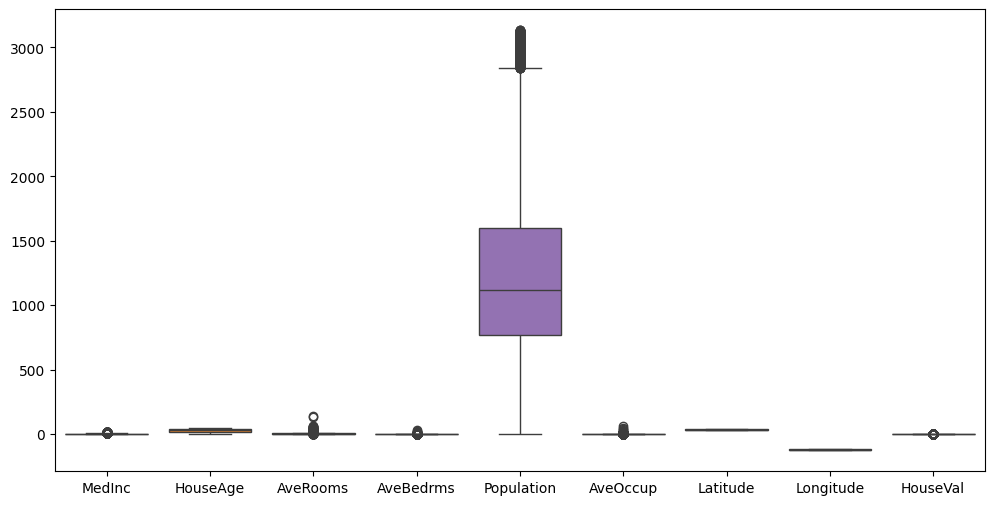

In [73]:
  clean_df = df[(df["Population"] >= lower_bound) & (df["Population"] <= upper_bound)]
  plt.figure(figsize=(12,6))
  sns.boxplot(data=clean_df)
  plt.show()

SPLITTING DATASET :

Dataset should be split into training and testing for model building

In [80]:
X=clean_df.drop(df[["HouseVal"]],axis=1)
y=clean_df["HouseVal"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


FEATURE SCALING:

Since the features are on different scales, some features may dominate others during model training. Feature scaling helps prevent this issue by bringing all features to a similar scale.

In [83]:
scale=StandardScaler()
X_train_scaled=scale.fit_transform(X_train)
X_test_scaled=scale.transform(X_test)


REGRESSION ALGORITHM IMPLEMENTATION

1.LINEAR REGRESSION:

Linear Regression model works by assuming relationship as a straight line


In [91]:
LR=LinearRegression()
LR.fit(X_train_scaled,y_train)

LinearRegression()

PREDICTION

In [103]:
y_pred_Lin=LR.predict(X_test_scaled)


MODEL EVALUATION:

> From evaluation matrics,we can see r2 score is low.it means model prediction is poor.model is biased




In [108]:
print("Root Mean Squared Error (RMSE):",root_mean_squared_error(y_test,y_pred_Lin))
print("Mean Absolute Error (MAE):",mean_absolute_error(y_test,y_pred_Lin))
print("R-squared Score (R2): ",r2_score(y_test,y_pred_Lin))


Root Mean Squared Error (RMSE): 0.7766003928204954
Mean Absolute Error (MAE): 0.5145445482913207
R-squared Score (R2):  0.5415803660018914


> Polynomial Regression:

Polynomial regression allows the model to bend like parabola,by making the input features into square of it.
for current dataset, this model is not working good as it's giving lower negative R2score resulting an most underfit model

In [167]:
poly=PolynomialFeatures(degree=2)
X_train_poly=poly.fit_transform(X_train_scaled)
X_test_poly=poly.transform(X_test_scaled)
PL = LinearRegression()
PL.fit(X_train_poly, y_train)
y_pred_poly = PL.predict(X_test_poly)
print("Root Mean Squared Error (RMSE):",root_mean_squared_error(y_test,y_pred_poly))
print("Mean Absolute Error (MAE):",mean_absolute_error(y_test,y_pred_poly))
print("R-squared Score (R2): ",r2_score(y_test,y_pred_poly))

Root Mean Squared Error (RMSE): 1.4180337238730996
Mean Absolute Error (MAE): 0.48105926375117236
R-squared Score (R2):  -0.5284143873291338


2.**Decision Tree Regressor**

It works by splitting the dataset into subsets by setting  condition rules to the features until a final decision happens

> TRAINING DATA

In [121]:
DT=DecisionTreeRegressor(random_state=42)
DT.fit(X_train_scaled,y_train)

DecisionTreeRegressor(random_state=42)

> PREDICTION

In [122]:
y_pred_Dec=DT.predict(X_test_scaled)

EVALUATION

From evaluation r2 score slightly increased.Prediction accuracy is getting increased than Linear Rigression.That means model can captures pattern from the dataset


In [123]:
print("Root Mean Squared Error (RMSE):",root_mean_squared_error(y_test,y_pred_Dec))
print("Mean Absolute Error (MAE):",mean_absolute_error(y_test,y_pred_Dec))
print("R-squared Score (R2): ",r2_score(y_test,y_pred_Dec))

Root Mean Squared Error (RMSE): 0.7207845150239266
Mean Absolute Error (MAE): 0.46376742607354077
R-squared Score (R2):  0.6051074921366213


**3.Random Forest Regressor**

It is one of the ensemble learning technique,where model creating n number of decision trees and based on the output recieved from each model ,it conclude the final output

TRAINING

In [141]:
RFR=RandomForestRegressor(n_estimators=50,random_state=42)
RFR.fit(X_train_scaled,y_train)

RandomForestRegressor(n_estimators=50, random_state=42)

PREDICTION

In [142]:
y_pred_RF=RFR.predict(X_test_scaled)

EVALUATION:
 Here r2 score value again increased.so that we can confirm prediction rate is increased from Decision Tree Model.Model performing well here

In [143]:
print("Root Mean Squared Error (RMSE):",root_mean_squared_error(y_test,y_pred_RF))
print("Mean Absolute Error (MAE):",mean_absolute_error(y_test,y_pred_RF))
print("R-squared Score (R2): ",r2_score(y_test,y_pred_RF))

Root Mean Squared Error (RMSE): 0.5200855752476716
Mean Absolute Error (MAE): 0.33851926202108507
R-squared Score (R2):  0.7944026012575717


**4.Gradient Boosting Regressor**

This is also an ensemble learning technique,here model builds new models sequentially, focuses on correcting errors made by previous models.

TRAINING

In [147]:
GBR=GradientBoostingRegressor(random_state=42)
GBR.fit(X_train_scaled,y_train)


GradientBoostingRegressor(random_state=42)

PREDICTION

In [148]:
y_pred_gbr=GBR.predict(X_test_scaled)

EVALUTAION
from this,we can see that R2 score remains same as Random Forest regressor method.prediction rate remain same.but have a slightly lesser value than Random Forest regressor method

In [149]:
print("Root Mean Squared Error (RMSE):",root_mean_squared_error(y_test,y_pred_gbr))
print("Mean Absolute Error (MAE):",mean_absolute_error(y_test,y_pred_gbr))
print("R-squared Score (R2): ",r2_score(y_test,y_pred_gbr))

Root Mean Squared Error (RMSE): 0.5411624455126144
Mean Absolute Error (MAE): 0.3751340575047826
R-squared Score (R2):  0.7774009535099137


**5.Support Vector Regressor (SVR)**:

Model works by finding the best boundary that separates the classes.SVM uses kernels to transform data into higher dimensions.

In [163]:
svr=SVR(kernel='rbf', C=1, gamma='scale')
svr.fit(X_train_scaled,y_train)

SVR(C=1)

PREDICTION

In [164]:
y_pred_svr=svr.predict(X_test_scaled)

EVALUATION

In [165]:
print("Root Mean Squared Error (RMSE):",root_mean_squared_error(y_test,y_pred_svr))
print("Mean Absolute Error (MAE):",mean_absolute_error(y_test,y_pred_svr))
print("R-squared Score (R2): ",r2_score(y_test,y_pred_svr))

Root Mean Squared Error (RMSE): 0.5504224821446477
Mean Absolute Error (MAE): 0.36978743111228984
R-squared Score (R2):  0.7697178225927216


COMPARING MODEL PERFORMANCE:

Here,from the result,we can say that for given california housing dataset,Random forest Algorithm is working better than others.Having high accuracy and performance.

the worst algorithm considers as linear regression,in which polynomial regression is very weak because of high negative value in R2 score.Model performance is very bad

In [174]:
print("POLYNOMIAL REGRESSION- R-squared Score (R2): ",r2_score(y_test,y_pred_poly))
print("LINEAR REGRESSION - R-squared Score (R2):    ",r2_score(y_test,y_pred_Lin))
print("DECISION TREE R-squared Score (R2):           ",r2_score(y_test,y_pred_Dec))
print("RANDOM FOREST REGRESSION R-squared Score (R2):",r2_score(y_test,y_pred_RF))
print("GRADIENT BOOSTING REGRESSION R-squared Score :",r2_score(y_test,y_pred_gbr))
print("SUPPORT VECTOR REGRESSION R-squared Score(R2):",r2_score(y_test,y_pred_svr))

POLYNOMIAL REGRESSION- R-squared Score (R2):  -0.5284143873291338
LINEAR REGRESSION - R-squared Score (R2):     0.5415803660018914
DECISION TREE R-squared Score (R2):            0.6051074921366213
RANDOM FOREST REGRESSION R-squared Score (R2): 0.7944026012575717
GRADIENT BOOSTING REGRESSION R-squared Score : 0.7774009535099137
SUPPORT VECTOR REGRESSION R-squared Score(R2): 0.7697178225927216
